In [1]:
# ENTROPY COMPARISON
import pandas as pd, numpy as np
import os
from os import listdir
from os.path import isfile, join

os.chdir("..")

def get_all_files(mypath):
    onlyfiles = [join(mypath, f) for f in listdir(mypath) if isfile(join(mypath, f))]
    return onlyfiles

base_parquet_df = pd.read_parquet("data/eval_results/single_eval/Qwen2.5-14B_20250506T103820/results.parquet")
# e.g. plot average entropy per layer across correct answers
all_layers_ent = []
all_layers_lp = []
for _, row in base_parquet_df[base_parquet_df.correct].iterrows():
    data = np.load(row.tensor_path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
base_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
base_lp_df = pd.DataFrame(all_layers_lp)

R1_parquet_df = pd.read_parquet("data/eval_results/single_eval/DeepSeek-R1-Distill-Qwen-14B_20250506T103823/results.parquet")
# e.g. plot average entropy per layer across correct answers
all_layers_ent = []
all_layers_lp = []
for _, row in R1_parquet_df[R1_parquet_df.correct].iterrows():
    data = np.load(row.tensor_path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
R1_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
R1_lp_df = pd.DataFrame(all_layers_lp)

GRPO_parquet_df = pd.read_parquet("data/eval_results/single_eval/checkpoint-1500_20250506T103825/results.parquet")
# e.g. plot average entropy per layer across correct answers
all_layers_ent = []
all_layers_lp = []
for _, row in GRPO_parquet_df[GRPO_parquet_df.correct].iterrows():
    data = np.load(row.tensor_path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
GRPO_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
GRPO_lp_df = pd.DataFrame(all_layers_lp)

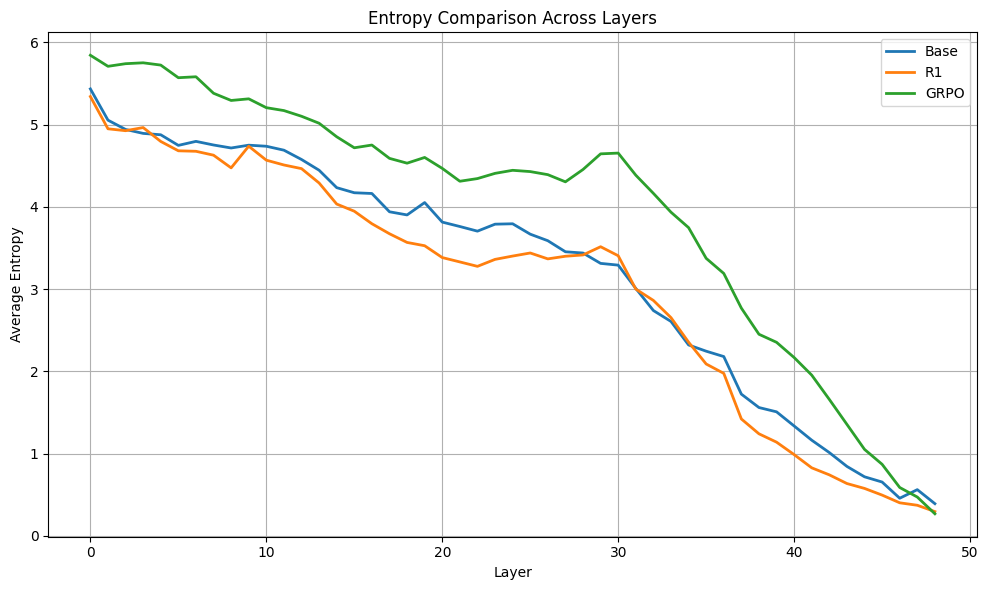

In [2]:
import matplotlib.pyplot as plt

# Compute means
base_mean = base_ent_df.mean()
R1_mean = R1_ent_df.mean()
GRPO_mean = GRPO_ent_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(R1_mean, label="R1", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Entropy")
plt.title("Entropy Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


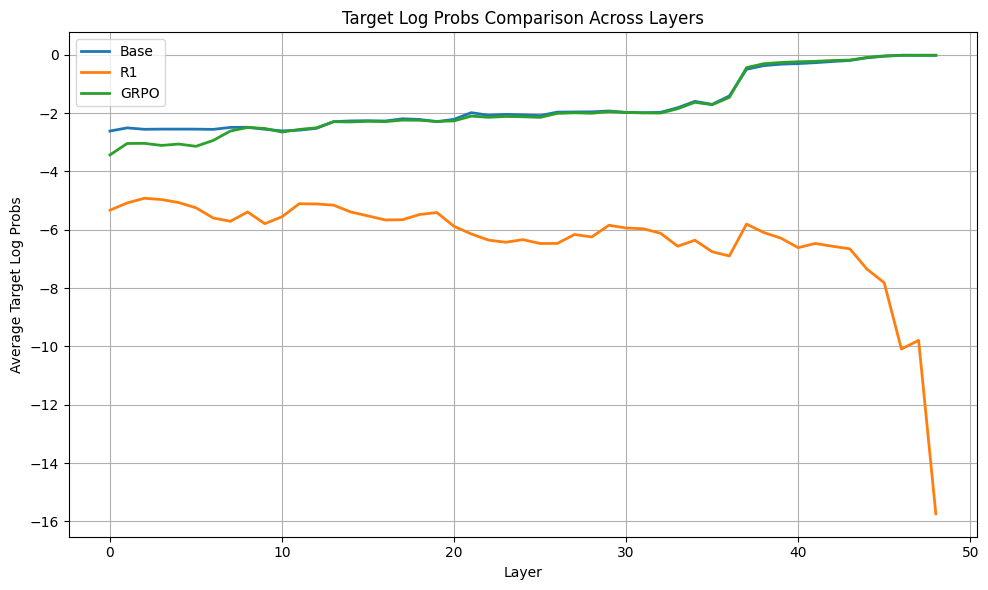

In [3]:
# Compute means
base_mean = base_lp_df.mean()
R1_mean = R1_lp_df.mean()
GRPO_mean = GRPO_lp_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(R1_mean, label="R1", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Ahora plot de solo base y grpo

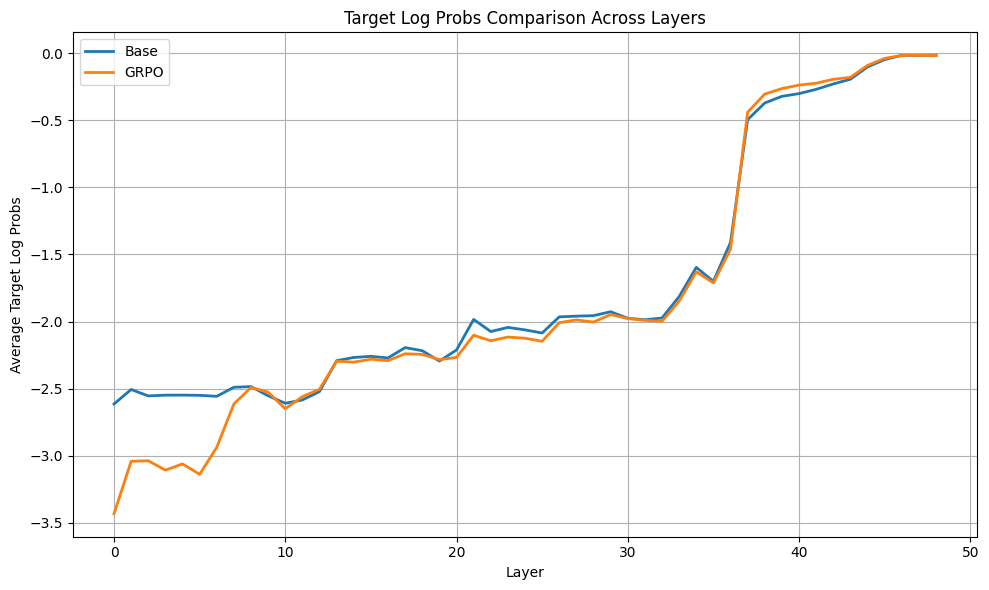

In [4]:
# Compute means
base_mean = base_lp_df.mean()
GRPO_mean = GRPO_lp_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

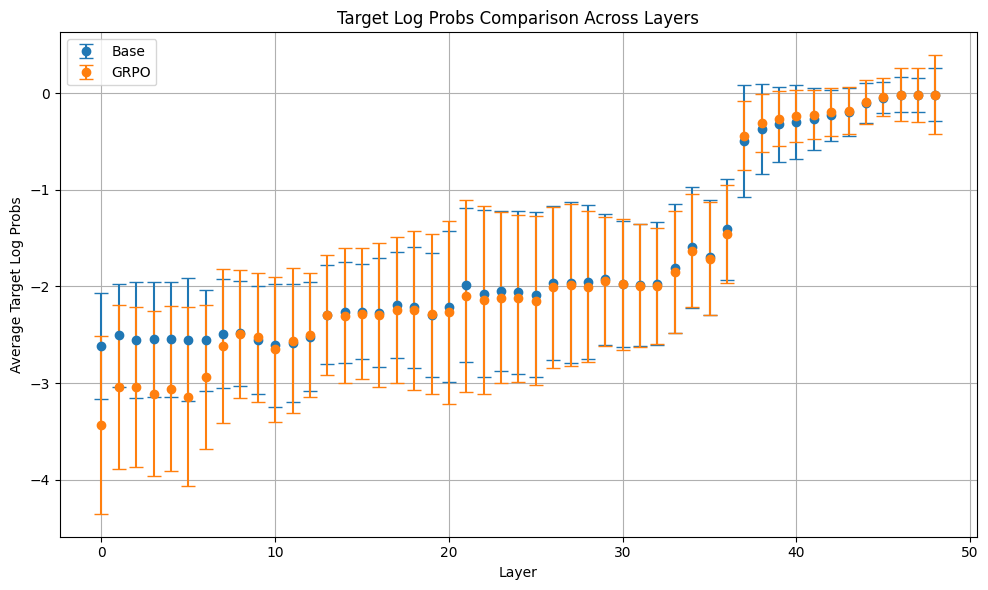

In [5]:
# Compute means and standard deviations
base_mean = base_lp_df.mean()
base_std = base_lp_df.std()
GRPO_mean = GRPO_lp_df.mean()
GRPO_std = GRPO_lp_df.std()

# X-axis: layer indices
layers = np.arange(len(base_mean))

# Plot with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(layers, base_mean, yerr=base_std, fmt='o', capsize=5, label="Base")
plt.errorbar(layers, GRPO_mean, yerr=GRPO_std, fmt='o', capsize=5, label="GRPO")

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:
def get_entropy_log_probs(df):
    all_layers_ent = []
    all_layers_lp = []
    for _, row in df.iterrows():
        data = np.load(row.tensor_path)
        ent = data["entropy"]
        log_probs = data["log_probs"]
        all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
        all_layers_lp.append(log_probs)          # (num_layers,)
    ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
    lp_df = pd.DataFrame(all_layers_lp)
    return ent_df, lp_df

base_ent_df, base_lp_df = get_entropy_log_probs(base_parquet_df[~base_parquet_df.correct])
R1_ent_df, R1_lp_df = get_entropy_log_probs(R1_parquet_df[~R1_parquet_df.correct])
GRPO_ent_df, GRPO_lp_df = get_entropy_log_probs(GRPO_parquet_df[~GRPO_parquet_df.correct])

In [7]:
base_lp_df.shape

(230, 49)

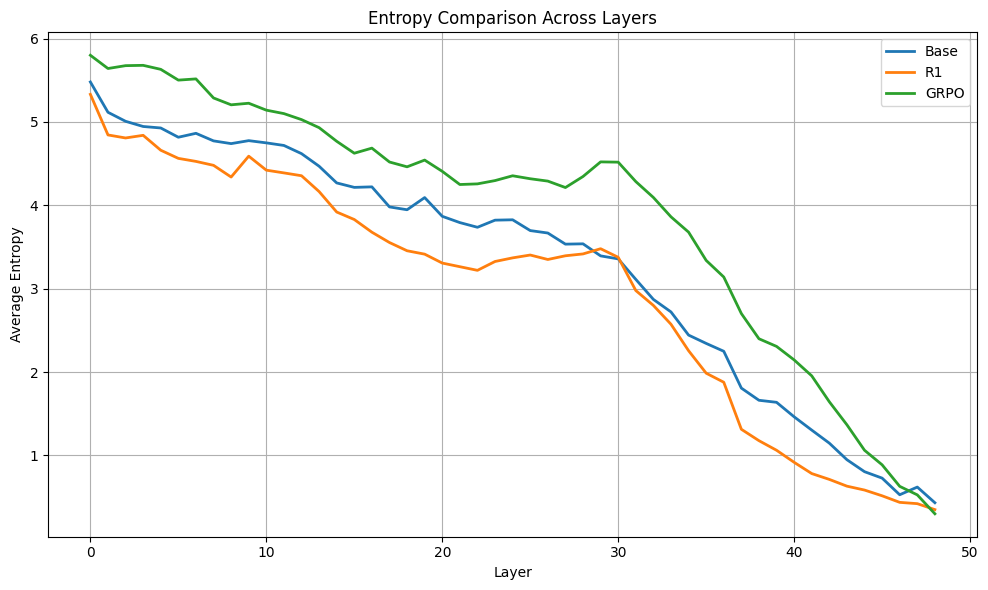

In [8]:
# Compute means
base_mean = base_ent_df.mean()
R1_mean = R1_ent_df.mean()
GRPO_mean = GRPO_ent_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(R1_mean, label="R1", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Entropy")
plt.title("Entropy Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

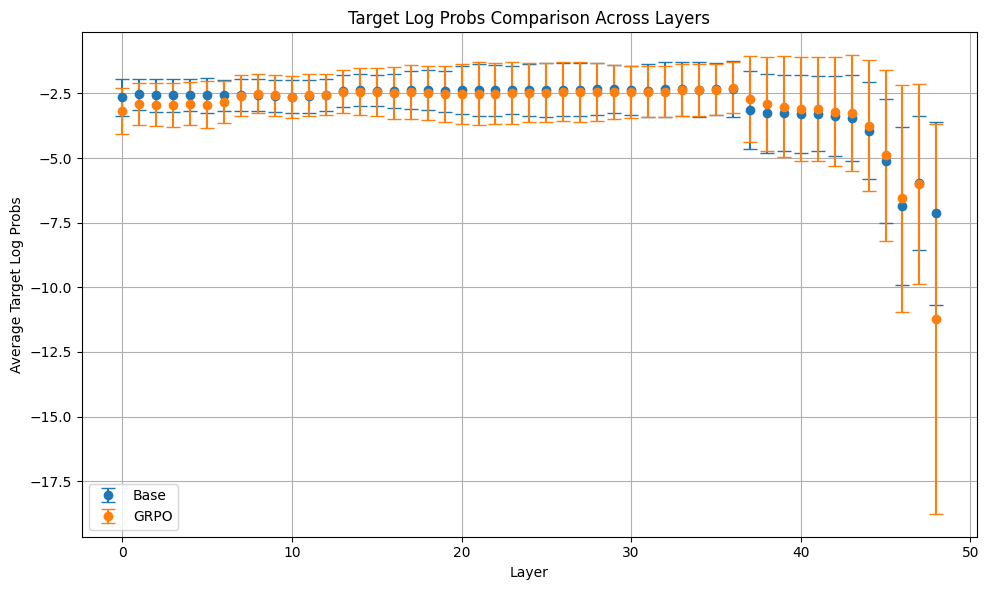

In [9]:
# Compute means and standard deviations
base_mean = base_lp_df.mean()
base_std = base_lp_df.std()
GRPO_mean = GRPO_lp_df.mean()
GRPO_std = GRPO_lp_df.std()

# X-axis: layer indices
layers = np.arange(len(base_mean))

# Plot with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(layers, base_mean, yerr=base_std, fmt='o', capsize=5, label="Base")
plt.errorbar(layers, GRPO_mean, yerr=GRPO_std, fmt='o', capsize=5, label="GRPO")

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:
base_parquet_df.correct.value_counts(), R1_parquet_df.correct.value_counts(), GRPO_parquet_df.correct.value_counts()

(correct
 True     1089
 False     230
 Name: count, dtype: int64,
 correct
 False    802
 True     517
 Name: count, dtype: int64,
 correct
 True     1139
 False     180
 Name: count, dtype: int64)

Ahora los que grpo hace bien pero base no

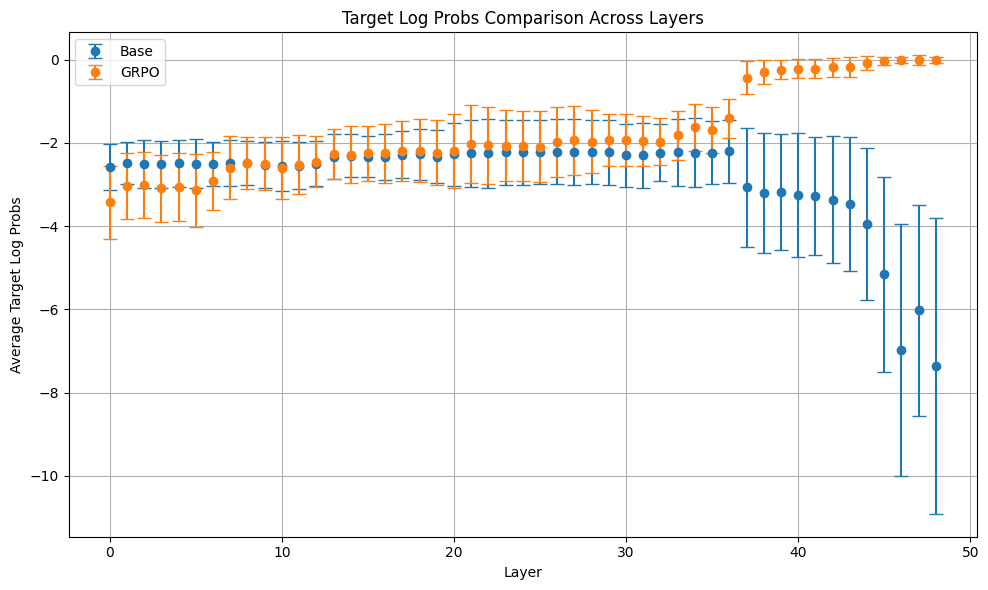

In [11]:
base_ent_df, base_lp_df = get_entropy_log_probs(base_parquet_df[(~base_parquet_df.correct) & (GRPO_parquet_df.correct)])
GRPO_ent_df, GRPO_lp_df = get_entropy_log_probs(GRPO_parquet_df[(~base_parquet_df.correct) & (GRPO_parquet_df.correct)])

# Compute means and standard deviations
base_mean = base_lp_df.mean()
base_std = base_lp_df.std()
GRPO_mean = GRPO_lp_df.mean()
GRPO_std = GRPO_lp_df.std()

# X-axis: layer indices
layers = np.arange(len(base_mean))

# Plot with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(layers, base_mean, yerr=base_std, fmt='o', capsize=5, label="Base")
plt.errorbar(layers, GRPO_mean, yerr=GRPO_std, fmt='o', capsize=5, label="GRPO")

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Y viceversa

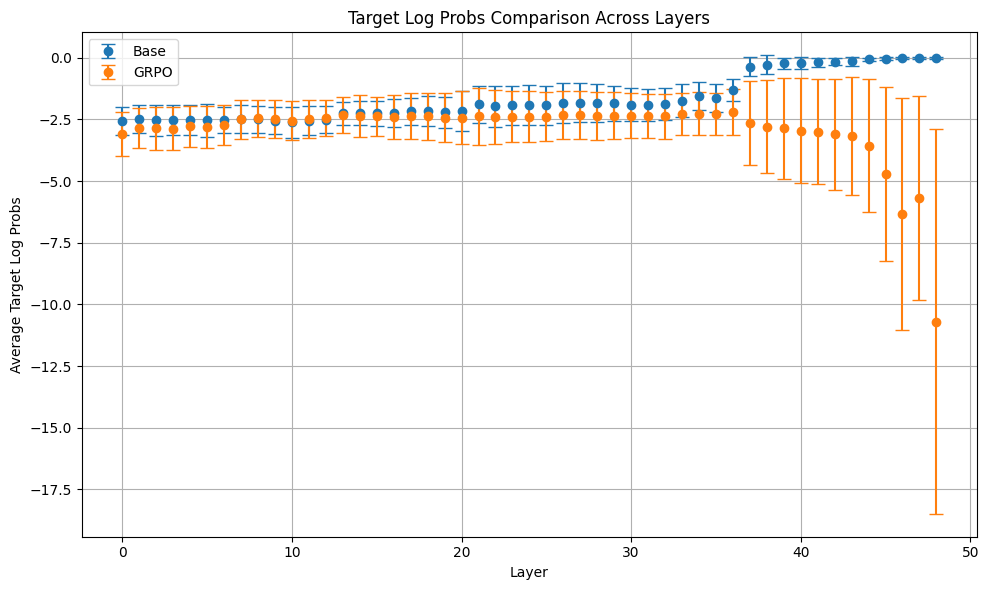

In [12]:
base_ent_df, base_lp_df = get_entropy_log_probs(base_parquet_df[(base_parquet_df.correct) & (~GRPO_parquet_df.correct)])
GRPO_ent_df, GRPO_lp_df = get_entropy_log_probs(GRPO_parquet_df[(base_parquet_df.correct) & (~GRPO_parquet_df.correct)])

# Compute means and standard deviations
base_mean = base_lp_df.mean()
base_std = base_lp_df.std()
GRPO_mean = GRPO_lp_df.mean()
GRPO_std = GRPO_lp_df.std()

# X-axis: layer indices
layers = np.arange(len(base_mean))

# Plot with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(layers, base_mean, yerr=base_std, fmt='o', capsize=5, label="Base")
plt.errorbar(layers, GRPO_mean, yerr=GRPO_std, fmt='o', capsize=5, label="GRPO")

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:
sum((base_parquet_df.correct) & (~GRPO_parquet_df.correct))

100

In [14]:
sum((~base_parquet_df.correct) & (GRPO_parquet_df.correct))

150

Voy a comprobar que el R1 estaba fallando porque no le doy bastantes tokens

Voy a ver si lo del R1 en la nueva evaluación cambia mucho

In [17]:
all_layers_ent = []
all_layers_lp = []
for path in get_all_files("data/eval_results/single_eval/DeepSeek-R1-Distill-Qwen-14B_20250507T144535/tensors"): # There's no way of getting which ones are correct in here
    data = np.load(path)
    ent = data["entropy"]
    log_probs = data["log_probs"]
    all_layers_ent.append(ent.mean(axis=1))          # (num_layers,)
    all_layers_lp.append(log_probs)          # (num_layers,)
R1_ent_df = pd.DataFrame(all_layers_ent)              # shape: n × num_layers
R1_lp_df = pd.DataFrame(all_layers_lp)

In [ ]:
R1_lp_df.columns

RangeIndex(start=0, stop=49, step=1)

<Axes: >

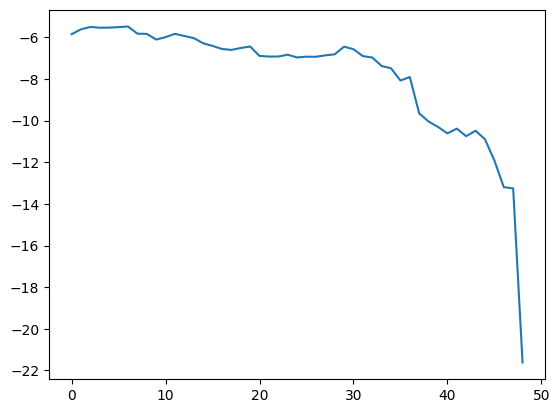

In [15]:
R1_lp_df.mean().plot()

### Con esto no estoy nada seguro de que esté pillando bien dónde acaba la respuesta :S

In [ ]:
correct_R1_lp_df = R1_lp_df["49"]

KeyError: 49